In [1]:
from pathlib import Path
from datetime import datetime, timezone
import sys
import json
import time

import numpy as np
import pandas as pd
import torch
import cvxpy as cp
import matplotlib.pyplot as plt

# Locate your awdro project.
current = Path.cwd().resolve()

required_folders = [
    "hedging",
    "path simulation",
    "inner maximization",
    "outer minimization",
]

root = next(
    (
        folder
        for folder in (current, *current.parents)
        if all((folder / name).is_dir() for name in required_folders)
    ),
    None,
)

if root is None:
    raise FileNotFoundError(
        f"Could not locate awdro from {current}. "
        "Save and open this notebook inside your awdro project."
    )

# Make your modules importable.
for folder in [root, *(root / name for name in required_folders)]:
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))

from Heston import Heston
from SuperhedgingProblem import SuperhedgingProblem
from NonrectangularSolver import NonrectangularSolver
from RectangularSolver import RectangularSolver
from RelaxedSuperhedgingSolver import RelaxedSuperhedgingSolver

# Check that the updated adaptive methods are available.
for method in [
    "_build_history_groups",
    "_build_adaptive_gains_matrix",
    "solve_adaptive_hedge_nonrectangular",
    "solve_adaptive_hedge_rectangular",
]:
    if not hasattr(RelaxedSuperhedgingSolver, method):
        raise AttributeError(
            f"Missing method: {method}. "
            "Save your updated Python file, restart the kernel, and rerun."
        )

if "HIGHS" not in cp.installed_solvers():
    raise RuntimeError(
        "HiGHS is unavailable. Run %pip install highspy, "
        "then restart the notebook kernel."
    )

# Constant-parameter Heston reference model.
model = Heston(
    s0=100.0,
    v0=0.04,
    mu=0.0,
    kappa=2.0,
    theta=0.04,
    vol_of_vol=0.3,
    rho=-0.7,
)

print("Project root:", root)
print("Adaptive solvers and HiGHS are available.")
print("Heston model initialized.")

Project root: /Users/jacve/Git/awdro
Adaptive solvers and HiGHS are available.
Heston model initialized.


In [2]:
import json
import time
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

maturity = 1.0
strike = 100.0

capital_bounds = (0.0, 50.0)
holding_bounds = (-2.0, 2.0)

# A new directory prevents accidentally mixing different experiments.
run_name = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
study_dir = root / "results" / f"research_study_{run_name}"
study_dir.mkdir(parents=True, exist_ok=True)


def call_payoff(paths):
    return torch.clamp(paths[:, -1, 0] - strike, min=0.0)


def digital_payoff(paths):
    return 10.0 * (paths[:, -1, 0] > strike).to(paths.dtype)


payoffs = {
    "European call": call_payoff,
    "Digital call": digital_payoff,
}

# Main study: vary budget and penalty on a fixed discretization.
# Robustness study: change one discretization dimension at a time.
studies = [
    {
        "name": "main",
        "n_steps": 2,
        "branches": 2,
        "seeds": list(range(42, 52)),
        "budgets": [0.0, 0.5, 1.0, 2.0],
        "penalties": [2.0, 5.0, 10.0, 25.0, 50.0],
    },
    {
        "name": "more_steps",
        "n_steps": 3,
        "branches": 2,
        "seeds": list(range(42, 47)),
        "budgets": [0.5, 1.0],
        "penalties": [2.0, 10.0],
    },
    {
        "name": "more_branches",
        "n_steps": 2,
        "branches": 3,
        "seeds": list(range(42, 47)),
        "budgets": [0.5, 1.0],
        "penalties": [2.0, 10.0],
    },
]

metadata = {
    "maturity": maturity,
    "strike": strike,
    "digital_payout": 10.0,
    "capital_bounds": capital_bounds,
    "holding_bounds": holding_bounds,
    "hedge": "one holding per observed stock-variance history",
    "transport": "one-way causal W2",
    "cost": "unweighted sum of squared stock and variance differences",
    "studies": studies,
    "heston": {
        name: float(getattr(model, name))
        for name in [
            "s0", "v0", "mu", "kappa",
            "theta", "vol_of_vol", "rho",
        ]
    },
}

(study_dir / "settings.json").write_text(
    json.dumps(metadata, indent=2)
)

total_pairs = sum(
    len(s["seeds"])
    * len(s["budgets"])
    * len(s["penalties"])
    * len(payoffs)
    for s in studies
)

print("Paired comparisons:", total_pairs)
print("Results directory:", study_dir)

Paired comparisons: 480
Results directory: /Users/jacve/Git/awdro/results/research_study_20261031_104550


In [3]:
records = []
failures = []
completed = 0

for study in studies:
    n_steps = study["n_steps"]
    branches = study["branches"]

    times = np.linspace(0.0, maturity, n_steps + 1)

    for seed in study["seeds"]:
        discretization = {
            "reference_branches": branches,
            "seed": seed,
        }

        for budget in study["budgets"]:
            construction_start = time.perf_counter()

            rectangular = RectangularSolver(
                model, times, budget, discretization
            )
            nonrectangular = NonrectangularSolver(
                model, times, budget, discretization
            )

            construction_seconds = (
                time.perf_counter() - construction_start
            )

            # The two methods must use the same finite model.
            np.testing.assert_array_equal(
                np.asarray([
                    node["state"]
                    for node in rectangular.reference_nodes
                ]),
                np.asarray([
                    node["state"]
                    for node in nonrectangular.reference_nodes
                ]),
            )

            for t in range(n_steps + 1):
                np.testing.assert_array_equal(
                    rectangular.adversarial_candidates[t],
                    nonrectangular.adversarial_candidates[t],
                )

            n_reference = len(rectangular.reference_paths)
            n_adversarial = len(rectangular.adversarial_paths)

            for payoff_name, payoff_fn in payoffs.items():
                problem = SuperhedgingProblem(
                    payoff=payoff_fn,
                    trading_times=times,
                )

                for penalty in study["penalties"]:
                    configuration = {
                        "study": study["name"],
                        "payoff": payoff_name,
                        "seed": seed,
                        "budget": budget,
                        "penalty": penalty,
                        "n_steps": n_steps,
                        "branches": branches,
                        "maturity": maturity,
                    }

                    outer = RelaxedSuperhedgingSolver(
                        problem=problem,
                        inner_solver=nonrectangular,
                        penalty=penalty,
                    )

                    try:
                        start = time.perf_counter()

                        nr = outer.solve_adaptive_hedge_nonrectangular(
                            rectangular,
                            capital_bounds,
                            holding_bounds,
                        )

                        nr_seconds = time.perf_counter() - start
                        start = time.perf_counter()

                        rect = outer.solve_adaptive_hedge_rectangular(
                            rectangular,
                            capital_bounds,
                            holding_bounds,
                        )

                        rect_seconds = time.perf_counter() - start

                        for answer in [nr, rect]:
                            if not np.isfinite([
                                answer["capital"],
                                answer["value"],
                                answer["worst_case_shortfall"],
                            ]).all():
                                raise RuntimeError("Nonfinite scalar result.")

                            if not np.isfinite(answer["holdings"]).all():
                                raise RuntimeError("Nonfinite holdings.")

                        gap = rect["value"] - nr["value"]
                        tolerance = 1e-4 * max(
                            1.0, abs(rect["value"]), abs(nr["value"])
                        )

                        if gap < -tolerance:
                            raise RuntimeError(
                                f"Negative gap beyond tolerance: {gap}"
                            )

                        if budget == 0:
                            np.testing.assert_allclose(
                                rect["value"],
                                nr["value"],
                                rtol=1e-5,
                                atol=1e-4,
                            )

                        record = {
                            **configuration,
                            "n_reference_paths": n_reference,
                            "n_adversarial_paths": n_adversarial,
                            "n_coupling_variables": n_reference * n_adversarial,
                            "n_hedge_variables": len(rect["holdings"]),
                            "nonrectangular_value": nr["value"],
                            "rectangular_value": rect["value"],
                            "gap": gap,
                            "capital_gap": (
                                rect["capital"] - nr["capital"]
                            ),
                            "penalized_shortfall_gap": penalty * (
                                rect["worst_case_shortfall"]
                                - nr["worst_case_shortfall"]
                            ),
                            "construction_seconds": construction_seconds,
                            "nonrectangular_seconds": nr_seconds,
                            "rectangular_seconds": rect_seconds,
                        }

                        for name, answer in [
                            ("nonrectangular", nr),
                            ("rectangular", rect),
                        ]:
                            holdings = np.asarray(answer["holdings"])

                            record[f"{name}_capital"] = answer["capital"]
                            record[f"{name}_shortfall"] = (
                                answer["worst_case_shortfall"]
                            )
                            record[f"{name}_capital_at_bound"] = bool(
                                np.isclose(
                                    answer["capital"],
                                    capital_bounds,
                                    rtol=0.0,
                                    atol=1e-4,
                                ).any()
                            )
                            record[f"{name}_holding_bound_count"] = int(
                                np.isclose(
                                    holdings[:, None],
                                    np.asarray(holding_bounds)[None, :],
                                    rtol=0.0,
                                    atol=1e-4,
                                ).any(axis=1).sum()
                            )

                        # Retain raw gaps, including tiny numerical negatives.
                        records.append(record)

                        solution_name = (
                            f"{study['name']}_seed{seed}_"
                            f"budget{budget:g}_penalty{penalty:g}_"
                            f"{payoff_name.replace(' ', '_')}.npz"
                        )

                        np.savez_compressed(
                            study_dir / solution_name,
                            nonrectangular_holdings=nr["holdings"],
                            rectangular_holdings=rect["holdings"],
                            offsets=rect["offsets"],
                            **{
                                f"histories_t{t}": histories
                                for t, histories in enumerate(
                                    rect["histories_by_time"]
                                )
                            },
                        )

                        print(
                            f"{configuration} | gap={gap:.6f} | "
                            f"time={nr_seconds + rect_seconds:.2f}s"
                        )

                    except Exception as error:
                        failures.append({
                            **configuration,
                            "error_type": type(error).__name__,
                            "error": str(error),
                        })
                        print("FAILED:", configuration, str(error))

                    completed += 1

                    pd.DataFrame(records).to_csv(
                        study_dir / "results.csv", index=False
                    )
                    pd.DataFrame(failures).to_csv(
                        study_dir / "failures.csv", index=False
                    )

                    print(f"Completed attempts: {completed}/{total_pairs}")

results = pd.DataFrame(records)
failure_results = pd.DataFrame(failures)

print("Successful pairs:", len(results))
print("Failed pairs:", len(failure_results))
display(failure_results)

{'study': 'main', 'payoff': 'European call', 'seed': 42, 'budget': 0.0, 'penalty': 2.0, 'n_steps': 2, 'branches': 2, 'maturity': 1.0} | gap=0.000000 | time=0.02s
Completed attempts: 1/480
{'study': 'main', 'payoff': 'European call', 'seed': 42, 'budget': 0.0, 'penalty': 5.0, 'n_steps': 2, 'branches': 2, 'maturity': 1.0} | gap=0.000000 | time=0.01s
Completed attempts: 2/480
{'study': 'main', 'payoff': 'European call', 'seed': 42, 'budget': 0.0, 'penalty': 10.0, 'n_steps': 2, 'branches': 2, 'maturity': 1.0} | gap=0.000000 | time=0.01s
Completed attempts: 3/480
{'study': 'main', 'payoff': 'European call', 'seed': 42, 'budget': 0.0, 'penalty': 25.0, 'n_steps': 2, 'branches': 2, 'maturity': 1.0} | gap=0.000000 | time=0.01s
Completed attempts: 4/480
{'study': 'main', 'payoff': 'European call', 'seed': 42, 'budget': 0.0, 'penalty': 50.0, 'n_steps': 2, 'branches': 2, 'maturity': 1.0} | gap=0.000000 | time=0.01s
Completed attempts: 5/480
{'study': 'main', 'payoff': 'Digital call', 'seed': 42, '

""


In [4]:
main = results[results["study"] == "main"].copy()

summary = (
    main.groupby(["payoff", "budget", "penalty"], as_index=False)
    .agg(
        n_seeds=("seed", "nunique"),
        gap_mean=("gap", "mean"),
        gap_median=("gap", "median"),
        gap_min=("gap", "min"),
        gap_max=("gap", "max"),
        nonrectangular_mean=("nonrectangular_value", "mean"),
        rectangular_mean=("rectangular_value", "mean"),
        nonrectangular_shortfall=("nonrectangular_shortfall", "mean"),
        rectangular_shortfall=("rectangular_shortfall", "mean"),
    )
)

summary.to_csv(study_dir / "main_summary.csv", index=False)

display(summary)

,payoff,budget,penalty,n_seeds,gap_mean,gap_median,gap_min,gap_max,nonrectangular_mean,rectangular_mean,nonrectangular_shortfall,rectangular_shortfall
0,Digital call,0.0,2.0,10,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.052955,0.052955,0.000000,0.000000
1,Digital call,0.0,5.0,10,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.052955,0.052955,0.000000,0.000000
2,Digital call,0.0,10.0,10,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.052955,0.052955,0.000000,0.000000
3,Digital call,0.0,25.0,10,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.052955,0.052955,0.000000,0.000000
4,Digital call,0.0,50.0,10,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.052955,0.052955,0.000000,0.000000
5,Digital call,0.5,2.0,10,2.538276e-03,-0.000000e+00,0.000000e+00,2.383510e-02,0.120425,0.122963,0.033735,0.035004
6,Digital call,0.5,5.0,10,6.345691e-03,-0.000000e+00,0.000000e+00,5.958775e-02,0.221630,0.227976,0.033735,0.035004
7,Digital call,0.5,10.0,10,1.269138e-02,-0.000000e+00,0.000000e+00,1.191755e-01,0.390305,0.402997,0.033735,0.035004
8,Digital call,0.5,25.0,10,3.167416e-02,-0.000000e+00,0.000000e+00,2.979388e-01,0.836128,0.867802,0.025941,0.027208
9,Digital call,0.5,50.0,10,5.724872e-02,-0.000000e+00,0.000000e+00,5.663017e-01,1.287685,1.344934,0.008717,0.009688


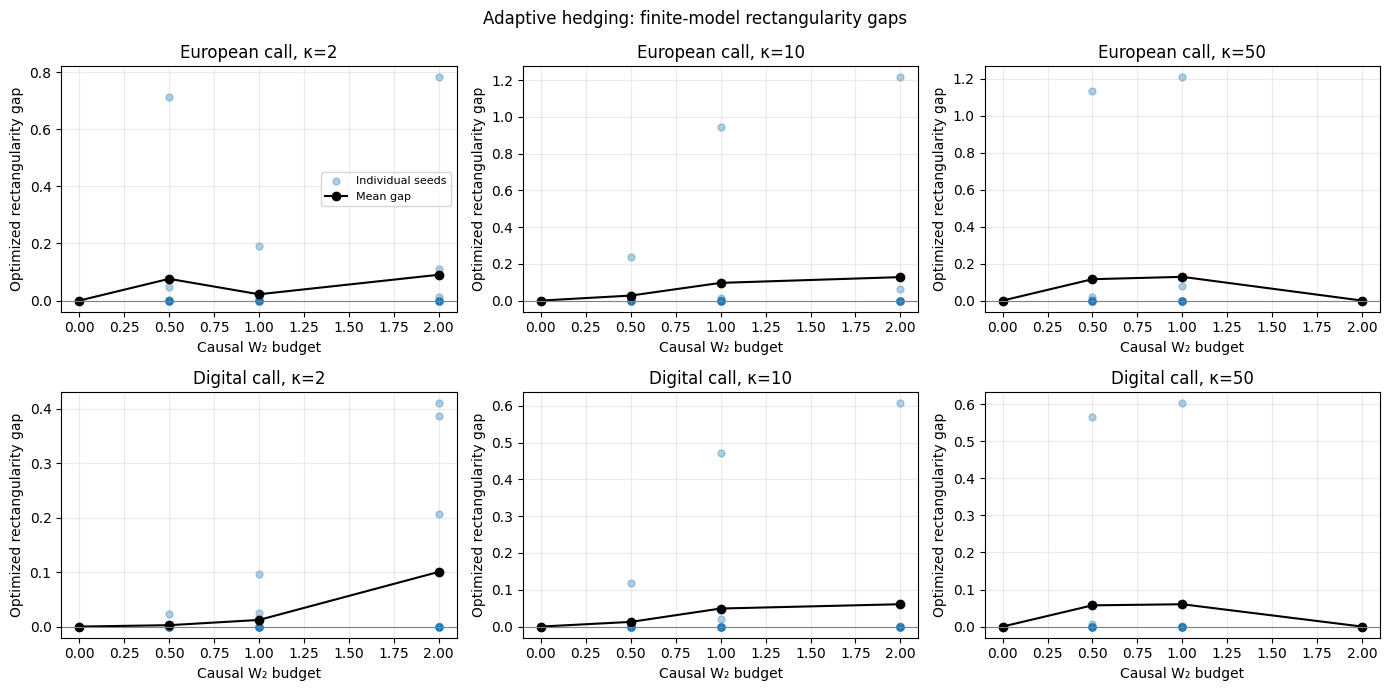

In [5]:
shown_penalties = [2.0, 10.0, 50.0]

fig, axes = plt.subplots(
    len(payoffs),
    len(shown_penalties),
    figsize=(14, 7),
    squeeze=False,
)

for row, payoff_name in enumerate(payoffs):
    for col, penalty in enumerate(shown_penalties):
        ax = axes[row, col]

        raw = main[
            (main["payoff"] == payoff_name)
            & (main["penalty"] == penalty)
        ]

        aggregated = summary[
            (summary["payoff"] == payoff_name)
            & (summary["penalty"] == penalty)
        ].sort_values("budget")

        ax.scatter(
            raw["budget"],
            raw["gap"],
            alpha=0.35,
            s=25,
            label="Individual seeds",
        )

        ax.plot(
            aggregated["budget"],
            aggregated["gap_mean"],
            color="black",
            marker="o",
            label="Mean gap",
        )

        ax.axhline(0.0, color="grey", linewidth=0.8)
        ax.set_title(f"{payoff_name}, κ={penalty:g}")
        ax.set_xlabel("Causal W₂ budget")
        ax.set_ylabel("Optimized rectangularity gap")
        ax.grid(alpha=0.25)

axes[0, 0].legend(fontsize=8)
fig.suptitle("Adaptive hedging: finite-model rectangularity gaps")
fig.tight_layout()

fig.savefig(
    study_dir / "gap_vs_budget.pdf",
    bbox_inches="tight",
)
plt.show()

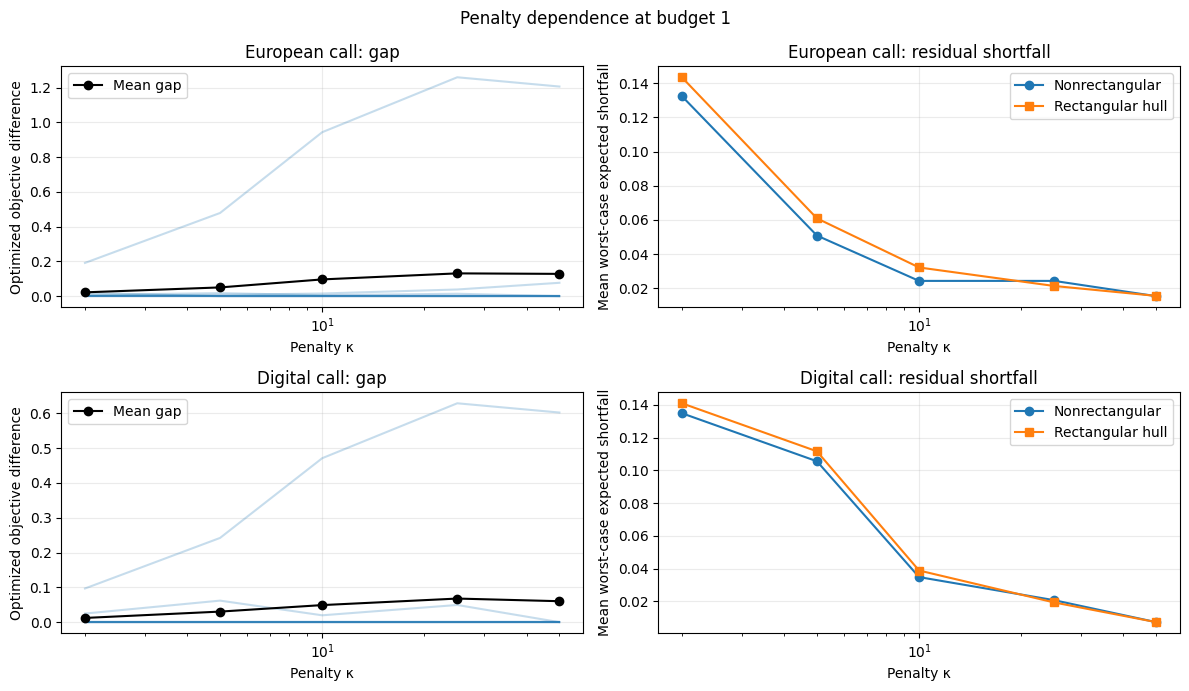

In [6]:
selected_budget = 1.0

fig, axes = plt.subplots(
    len(payoffs), 2,
    figsize=(12, 7),
    squeeze=False,
)

for row, payoff_name in enumerate(payoffs):
    raw = main[
        (main["payoff"] == payoff_name)
        & (main["budget"] == selected_budget)
    ]

    aggregated = summary[
        (summary["payoff"] == payoff_name)
        & (summary["budget"] == selected_budget)
    ].sort_values("penalty")

    for seed, group in raw.groupby("seed"):
        group = group.sort_values("penalty")
        axes[row, 0].plot(
            group["penalty"],
            group["gap"],
            color="tab:blue",
            alpha=0.25,
        )

    axes[row, 0].plot(
        aggregated["penalty"],
        aggregated["gap_mean"],
        color="black",
        marker="o",
        label="Mean gap",
    )

    axes[row, 1].plot(
        aggregated["penalty"],
        aggregated["nonrectangular_shortfall"],
        marker="o",
        label="Nonrectangular",
    )
    axes[row, 1].plot(
        aggregated["penalty"],
        aggregated["rectangular_shortfall"],
        marker="s",
        label="Rectangular hull",
    )

    axes[row, 0].set_title(f"{payoff_name}: gap")
    axes[row, 1].set_title(f"{payoff_name}: residual shortfall")
    axes[row, 0].set_ylabel("Optimized objective difference")
    axes[row, 1].set_ylabel("Mean worst-case expected shortfall")

    for ax in axes[row]:
        ax.set_xscale("log")
        ax.set_xlabel("Penalty κ")
        ax.grid(alpha=0.25)
        ax.legend()

fig.suptitle(f"Penalty dependence at budget {selected_budget:g}")
fig.tight_layout()

fig.savefig(
    study_dir / "penalty_and_shortfall.pdf",
    bbox_inches="tight",
)
plt.show()

In [7]:
common = results[
    results["seed"].isin(range(42, 47))
    & results["budget"].isin([0.5, 1.0])
    & results["penalty"].isin([2.0, 10.0])
]

robustness = (
    common.groupby(
        ["study", "n_steps", "branches", "payoff", "budget", "penalty"],
        as_index=False,
    )
    .agg(
        n_seeds=("seed", "nunique"),
        gap_mean=("gap", "mean"),
        gap_median=("gap", "median"),
        gap_min=("gap", "min"),
        gap_max=("gap", "max"),
        rectangular_seconds=("rectangular_seconds", "median"),
        nonrectangular_seconds=("nonrectangular_seconds", "median"),
    )
)

robustness.to_csv(
    study_dir / "discretization_comparison.csv",
    index=False,
)

display(robustness)

,study,n_steps,branches,payoff,budget,penalty,n_seeds,gap_mean,gap_median,gap_min,gap_max,rectangular_seconds,nonrectangular_seconds
0,main,2,2,Digital call,0.5,2.0,5,0.005077,6.347458e-07,0.000000,0.023835,0.009759,0.002745
1,main,2,2,Digital call,0.5,10.0,5,0.025383,3.173729e-06,0.000000,0.119176,0.009212,0.003045
2,main,2,2,Digital call,1.0,2.0,5,0.024300,1.012942e-05,0.000000,0.096735,0.009258,0.002713
3,main,2,2,Digital call,1.0,10.0,5,0.098101,5.064711e-05,0.000000,0.470710,0.009058,0.002816
4,main,2,2,European call,0.5,2.0,5,0.009762,4.397173e-04,0.000000,0.047606,0.009568,0.002553
5,main,2,2,European call,0.5,10.0,5,0.048812,2.198586e-03,0.000000,0.238028,0.009044,0.002720
6,main,2,2,European call,1.0,2.0,5,0.040301,3.079020e-03,0.000000,0.191392,0.009383,0.002645
7,main,2,2,European call,1.0,10.0,5,0.192830,5.611607e-03,0.000000,0.943144,0.009763,0.002657
8,more_branches,2,3,Digital call,0.5,2.0,5,0.828300,1.151360e-01,0.024256,3.341862,0.034411,0.003455
9,more_branches,2,3,Digital call,0.5,10.0,5,0.021350,1.340040e-04,0.000000,0.103702,0.034519,0.003329


In [8]:
# Imports and project location
from pathlib import Path
import sys
import time
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch
import cvxpy as cp
import matplotlib.pyplot as plt

required_folders = [
    "hedging",
    "path simulation",
    "inner maximization",
    "outer minimization",
]

current = Path.cwd().resolve()
root = next(
    (
        folder
        for folder in (current, *current.parents)
        if all((folder / name).is_dir() for name in required_folders)
    ),
    None,
)

if root is None:
    raise RuntimeError("Run this notebook inside your awdro project.")

for folder in [root] + [root / name for name in required_folders]:
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))

from Heston import Heston
from SuperhedgingProblem import SuperhedgingProblem
from NonrectangularSolver import NonrectangularSolver
from RectangularSolver import RectangularSolver
from RelaxedSuperhedgingSolver import RelaxedSuperhedgingSolver

if "HIGHS" not in cp.installed_solvers():
    raise RuntimeError(
        "Install HiGHS using %pip install highspy, then restart the kernel."
    )

In [9]:
# Fixed experiment configuration
N_SEEDS = 100
SEEDS = range(1000, 1000 + N_SEEDS)

PAYOFF = "european_call"  # Or "digital_call"
STRIKE = 100.0
DIGITAL_PAYOUT = 10.0

MATURITY = 1.0
N_STEPS = 2
BRANCHES = 2
BUDGET = 1.0
PENALTY = 10.0

CAPITAL_BOUNDS = (0.0, 50.0)
HOLDING_BOUNDS = (-2.0, 2.0)

# Numerical diagnostic threshold, not a certified solver error bound.
ABS_TOL = 1e-5
REL_TOL = 1e-5

times = np.linspace(0.0, MATURITY, N_STEPS + 1)

model = Heston(
    s0=100.0,
    v0=0.04,
    mu=0.0,
    kappa=2.0,
    theta=0.04,
    vol_of_vol=0.3,
    rho=-0.7,
)


def payoff(paths):
    terminal_stock = paths[:, -1, 0]

    if PAYOFF == "european_call":
        return torch.clamp(terminal_stock - STRIKE, min=0.0)

    if PAYOFF == "digital_call":
        return DIGITAL_PAYOUT * (
            terminal_stock > STRIKE
        ).to(dtype=paths.dtype)

    raise ValueError(f"Unknown payoff: {PAYOFF}")


problem = SuperhedgingProblem(
    payoff=payoff,
    trading_times=times,
)

timestamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
output_dir = root / "results" / f"paired_seeds_{PAYOFF}_{timestamp}"
output_dir.mkdir(parents=True, exist_ok=True)

configuration = {
    "payoff": PAYOFF,
    "strike": STRIKE,
    "digital_payout": DIGITAL_PAYOUT,
    "maturity": MATURITY,
    "n_steps": N_STEPS,
    "branches": BRANCHES,
    "budget": BUDGET,
    "penalty": PENALTY,
    "capital_bounds": CAPITAL_BOUNDS,
    "holding_bounds": HOLDING_BOUNDS,
    "n_seeds": N_SEEDS,
    "first_seed": SEEDS.start,
}

pd.Series(configuration).to_csv(output_dir / "configuration.csv")
print(f"Results will be saved to:\n{output_dir}")

Results will be saved to:
/Users/jacve/Git/awdro/results/paired_seeds_european_call_20261031_105407


In [10]:
# Run paired optimizations.
# Each seed uses the same reference tree and candidates in both solvers.

records = []

for run_number, seed in enumerate(SEEDS, start=1):
    started = time.perf_counter()

    row = {
        "seed": seed,
        "status": "failed",
        "stage": "construction",
        "error": "",
    }

    try:
        discretization = {
            "seed": seed,
            "reference_branches": BRANCHES,
        }

        rectangular = RectangularSolver(
            model, times, BUDGET, discretization
        )
        nonrectangular = NonrectangularSolver(
            model, times, BUDGET, discretization
        )

        row["stage"] = "shared_model_check"

        np.testing.assert_array_equal(
            np.asarray([
                node["state"] for node in rectangular.reference_nodes
            ]),
            np.asarray([
                node["state"] for node in nonrectangular.reference_nodes
            ]),
        )

        for t in range(len(times)):
            np.testing.assert_array_equal(
                rectangular.adversarial_candidates[t],
                nonrectangular.adversarial_candidates[t],
            )

        outer = RelaxedSuperhedgingSolver(
            problem=problem,
            inner_solver=nonrectangular,
            penalty=PENALTY,
        )

        row["stage"] = "nonrectangular_optimization"
        nr_started = time.perf_counter()

        # rectangular supplies the finite transport constraints;
        # this method solves the original nonrectangular problem.
        nr = outer.solve_adaptive_hedge_nonrectangular(
            rectangular,
            CAPITAL_BOUNDS,
            HOLDING_BOUNDS,
        )

        row["nonrectangular_seconds"] = time.perf_counter() - nr_started

        row["stage"] = "rectangular_optimization"
        rect_started = time.perf_counter()

        rect = outer.solve_adaptive_hedge_rectangular(
            rectangular,
            CAPITAL_BOUNDS,
            HOLDING_BOUNDS,
        )

        row["rectangular_seconds"] = time.perf_counter() - rect_started
        row["stage"] = "result_checks"

        for name, result in [
            ("nonrectangular", nr),
            ("rectangular", rect),
        ]:
            for key in ["value", "capital", "worst_case_shortfall"]:
                value = float(result[key])
                if not np.isfinite(value):
                    raise RuntimeError(f"{name}: nonfinite {key}.")
                row[f"{name}_{key}"] = value

            holdings = np.asarray(result["holdings"], dtype=float)

            if not np.isfinite(holdings).all():
                raise RuntimeError(f"{name}: nonfinite holdings.")

            bound_tol = ABS_TOL + REL_TOL * max(
                1.0, *map(abs, HOLDING_BOUNDS)
            )

            if (
                np.any(holdings < HOLDING_BOUNDS[0] - bound_tol)
                or np.any(holdings > HOLDING_BOUNDS[1] + bound_tol)
            ):
                raise RuntimeError(f"{name}: holding bounds violated.")

            row[f"{name}_holdings_at_bound"] = int(
                np.count_nonzero(
                    np.isclose(
                        holdings, HOLDING_BOUNDS[0],
                        atol=bound_tol, rtol=0.0,
                    )
                    | np.isclose(
                        holdings, HOLDING_BOUNDS[1],
                        atol=bound_tol, rtol=0.0,
                    )
                )
            )

            reconstructed = (
                float(result["capital"])
                + PENALTY * float(result["worst_case_shortfall"])
            )

            np.testing.assert_allclose(
                float(result["value"]),
                reconstructed,
                atol=ABS_TOL,
                rtol=REL_TOL,
            )

        gap = float(rect["value"] - nr["value"])
        tolerance = ABS_TOL + REL_TOL * max(
            1.0, abs(rect["value"]), abs(nr["value"])
        )

        row["gap"] = gap
        row["gap_tolerance"] = tolerance
        row["positive_above_tolerance"] = gap > tolerance

        # Preserve negative results for diagnosis; never clip them to zero.
        if gap < -tolerance:
            raise RuntimeError(
                f"Negative gap {gap:.6g} exceeds tolerance {tolerance:.6g}."
            )

        row["status"] = "ok"
        row["stage"] = "complete"

    except Exception as exc:
        row["error"] = f"{type(exc).__name__}: {exc}"
        print(f"Seed {seed} failed at {row['stage']}: {row['error']}")

    row["total_seconds"] = time.perf_counter() - started
    records.append(row)

    # Checkpoint after every seed.
    pd.DataFrame(records).to_csv(
        output_dir / "all_runs.csv", index=False
    )

    if run_number % 10 == 0 or run_number == N_SEEDS:
        successful = sum(record["status"] == "ok" for record in records)
        print(
            f"{run_number}/{N_SEEDS} completed | "
            f"{successful} successful | "
            f"{run_number - successful} failed"
        )

10/100 completed | 10 successful | 0 failed
20/100 completed | 20 successful | 0 failed
30/100 completed | 30 successful | 0 failed
40/100 completed | 40 successful | 0 failed
50/100 completed | 50 successful | 0 failed
60/100 completed | 60 successful | 0 failed
70/100 completed | 70 successful | 0 failed
80/100 completed | 80 successful | 0 failed
90/100 completed | 90 successful | 0 failed
100/100 completed | 100 successful | 0 failed


In [11]:
# Summaries and a paired-seed bootstrap confidence interval.
# Resample the seed-level gaps, not the two objectives independently.

results = pd.DataFrame(records)
successful = results.loc[results["status"] == "ok"].copy()
failures = results.loc[results["status"] != "ok"].copy()

if len(successful) < 2:
    raise RuntimeError("At least two successful seeds are needed.")

if len(failures):
    print(
        f"WARNING: {len(failures)} of {len(results)} runs failed. "
        "The statistics below describe successful runs only; "
        "resolve failures before interpreting them as the full experiment."
    )
    display(failures[["seed", "stage", "error"]])

gaps = successful["gap"].to_numpy(dtype=float)
n = len(gaps)

mean_gap = gaps.mean()
standard_error = gaps.std(ddof=1) / np.sqrt(n)

bootstrap_rng = np.random.default_rng(2026)
bootstrap_indices = bootstrap_rng.integers(
    0, n, size=(10_000, n)
)
bootstrap_means = gaps[bootstrap_indices].mean(axis=1)
ci_lower, ci_upper = np.quantile(bootstrap_means, [0.025, 0.975])

summary = pd.DataFrame([{
    "attempted_seeds": len(results),
    "successful_seeds": n,
    "failed_seeds": len(failures),
    "mean_gap": mean_gap,
    "mean_standard_error": standard_error,
    "bootstrap_CI95_lower": ci_lower,
    "bootstrap_CI95_upper": ci_upper,
    "median_gap": np.median(gaps),
    "gap_p10": np.quantile(gaps, 0.10),
    "gap_p90": np.quantile(gaps, 0.90),
    "minimum_gap": gaps.min(),
    "maximum_gap": gaps.max(),
    "fraction_positive_above_tolerance": (
        successful["positive_above_tolerance"].mean()
    ),
    "mean_nonrectangular_value": (
        successful["nonrectangular_value"].mean()
    ),
    "mean_rectangular_value": (
        successful["rectangular_value"].mean()
    ),
}])

summary.to_csv(output_dir / "summary.csv", index=False)
display(summary.T.rename(columns={0: "value"}))

,value
attempted_seeds,1.000000e+02
successful_seeds,1.000000e+02
failed_seeds,0.000000e+00
mean_gap,1.646721e-01
mean_standard_error,3.680189e-02
bootstrap_CI95_lower,9.774078e-02
bootstrap_CI95_upper,2.383506e-01
median_gap,0.000000e+00
gap_p10,-0.000000e+00
gap_p90,5.436113e-01


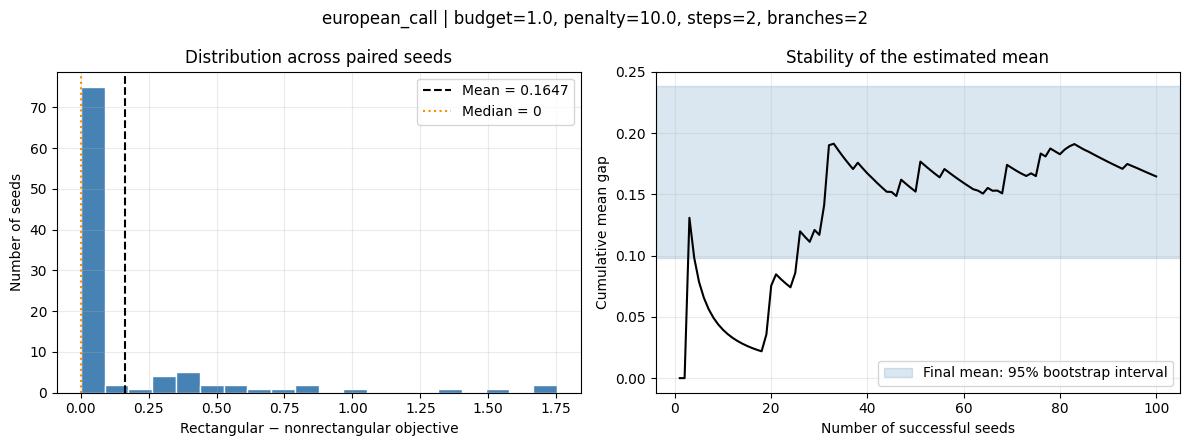

In [13]:
# Distribution and stability of the estimated mean

running_mean = np.cumsum(gaps) / np.arange(1, n + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(
    gaps,
    bins="auto",
    color="steelblue",
    edgecolor="white",
)
axes[0].axvline(
    mean_gap,
    color="black",
    linestyle="--",
    label=f"Mean = {mean_gap:.4g}",
)
axes[0].axvline(
    np.median(gaps),
    color="darkorange",
    linestyle=":",
    label=f"Median = {np.median(gaps):.4g}",
)
axes[0].set_xlabel("Rectangular − nonrectangular objective")
axes[0].set_ylabel("Number of seeds")
axes[0].set_title("Distribution across paired seeds")
axes[0].legend()

axes[1].plot(
    np.arange(1, n + 1),
    running_mean,
    color="black",
)
axes[1].axhspan(
    ci_lower,
    ci_upper,
    color="steelblue",
    alpha=0.2,
    label="Final mean: 95% bootstrap interval",
)
axes[1].set_xlabel("Number of successful seeds")
axes[1].set_ylabel("Cumulative mean gap")
axes[1].set_title("Stability of the estimated mean")
axes[1].legend()

for ax in axes:
    ax.grid(alpha=0.25)

fig.suptitle(
    f"{PAYOFF} | budget={BUDGET}, penalty={PENALTY}, "
    f"steps={N_STEPS}, branches={BRANCHES}"
)
fig.tight_layout()
fig.savefig(output_dir / "seed_gap_distribution.pdf", bbox_inches="tight")
plt.show()

In [14]:
# Preserve the previous two-branch results before running anything else.
baseline_results = results.copy(deep=True)

if BRANCHES != 2:
    raise ValueError("The baseline must be your two-branch experiment.")

if len(baseline_results) != N_SEEDS:
    raise ValueError("The baseline experiment is incomplete.")

baseline_results["branches"] = 2

comparison_dir = output_dir / "branch_comparison"
comparison_dir.mkdir(parents=True, exist_ok=True)

baseline_results.to_csv(
    comparison_dir / "branches_2.csv",
    index=False,
)

print(f"Baseline saved. Running {N_SEEDS} seeds with 3 branches.")

Baseline saved. Running 100 seeds with 3 branches.


In [15]:
three_branch_records = []

for run_number, seed in enumerate(SEEDS, start=1):
    started = time.perf_counter()

    row = {
        "seed": seed,
        "branches": 3,
        "status": "failed",
        "stage": "construction",
        "error": "",
    }

    try:
        discretization = {
            "seed": seed,
            "reference_branches": 3,
        }

        rectangular = RectangularSolver(
            model, times, BUDGET, discretization
        )
        nonrectangular = NonrectangularSolver(
            model, times, BUDGET, discretization
        )

        row["stage"] = "shared_model_check"

        np.testing.assert_array_equal(
            np.asarray([
                node["state"] for node in rectangular.reference_nodes
            ]),
            np.asarray([
                node["state"] for node in nonrectangular.reference_nodes
            ]),
        )

        for t in range(len(times)):
            np.testing.assert_array_equal(
                rectangular.adversarial_candidates[t],
                nonrectangular.adversarial_candidates[t],
            )

        outer = RelaxedSuperhedgingSolver(
            problem=problem,
            inner_solver=nonrectangular,
            penalty=PENALTY,
        )

        row["stage"] = "nonrectangular_optimization"
        optimization_started = time.perf_counter()

        nr = outer.solve_adaptive_hedge_nonrectangular(
            rectangular,
            CAPITAL_BOUNDS,
            HOLDING_BOUNDS,
        )

        row["nonrectangular_seconds"] = (
            time.perf_counter() - optimization_started
        )

        row["stage"] = "rectangular_optimization"
        optimization_started = time.perf_counter()

        rect = outer.solve_adaptive_hedge_rectangular(
            rectangular,
            CAPITAL_BOUNDS,
            HOLDING_BOUNDS,
        )

        row["rectangular_seconds"] = (
            time.perf_counter() - optimization_started
        )

        row["stage"] = "result_checks"

        for name, result in [
            ("nonrectangular", nr),
            ("rectangular", rect),
        ]:
            for key in ["value", "capital", "worst_case_shortfall"]:
                value = float(result[key])

                if not np.isfinite(value):
                    raise RuntimeError(f"{name}: nonfinite {key}.")

                row[f"{name}_{key}"] = value

            capital = float(result["capital"])
            holdings = np.asarray(result["holdings"], dtype=float)

            if not np.isfinite(holdings).all():
                raise RuntimeError(f"{name}: nonfinite holdings.")

            capital_tol = ABS_TOL + REL_TOL * max(
                1.0, *map(abs, CAPITAL_BOUNDS)
            )
            holding_tol = ABS_TOL + REL_TOL * max(
                1.0, *map(abs, HOLDING_BOUNDS)
            )

            if not (
                CAPITAL_BOUNDS[0] - capital_tol
                <= capital
                <= CAPITAL_BOUNDS[1] + capital_tol
            ):
                raise RuntimeError(f"{name}: capital bounds violated.")

            if (
                np.any(holdings < HOLDING_BOUNDS[0] - holding_tol)
                or np.any(holdings > HOLDING_BOUNDS[1] + holding_tol)
            ):
                raise RuntimeError(f"{name}: holding bounds violated.")

            row[f"{name}_holdings_at_bound"] = int(
                np.count_nonzero(
                    np.isclose(
                        holdings,
                        HOLDING_BOUNDS[0],
                        atol=holding_tol,
                        rtol=0.0,
                    )
                    | np.isclose(
                        holdings,
                        HOLDING_BOUNDS[1],
                        atol=holding_tol,
                        rtol=0.0,
                    )
                )
            )

            reconstructed = (
                capital
                + PENALTY * float(result["worst_case_shortfall"])
            )

            np.testing.assert_allclose(
                float(result["value"]),
                reconstructed,
                atol=ABS_TOL,
                rtol=REL_TOL,
            )

        gap = float(rect["value"] - nr["value"])

        tolerance = ABS_TOL + REL_TOL * max(
            1.0,
            abs(float(rect["value"])),
            abs(float(nr["value"])),
        )

        row["gap"] = gap
        row["gap_tolerance"] = tolerance
        row["positive_above_tolerance"] = gap > tolerance

        if gap < -tolerance:
            raise RuntimeError(
                f"Negative gap {gap:.6g} exceeds tolerance {tolerance:.6g}."
            )

        row["status"] = "ok"
        row["stage"] = "complete"

    except Exception as exc:
        row["error"] = f"{type(exc).__name__}: {exc}"
        print(
            f"Seed {seed} failed at {row['stage']}: {row['error']}"
        )

    row["total_seconds"] = time.perf_counter() - started
    three_branch_records.append(row)

    pd.DataFrame(three_branch_records).to_csv(
        comparison_dir / "branches_3.csv",
        index=False,
    )

    if run_number % 10 == 0 or run_number == N_SEEDS:
        successful_count = sum(
            record["status"] == "ok"
            for record in three_branch_records
        )

        print(
            f"{run_number}/{N_SEEDS} completed | "
            f"{successful_count} successful | "
            f"{run_number - successful_count} failed"
        )

three_branch_results = pd.DataFrame(three_branch_records)

10/100 completed | 10 successful | 0 failed
20/100 completed | 20 successful | 0 failed
30/100 completed | 30 successful | 0 failed
40/100 completed | 40 successful | 0 failed
50/100 completed | 50 successful | 0 failed
60/100 completed | 60 successful | 0 failed
70/100 completed | 70 successful | 0 failed
80/100 completed | 80 successful | 0 failed
90/100 completed | 90 successful | 0 failed
100/100 completed | 100 successful | 0 failed


In [16]:
combined_results = pd.concat(
    [baseline_results, three_branch_results],
    ignore_index=True,
)

combined_results.to_csv(
    comparison_dir / "combined_runs.csv",
    index=False,
)

summary_rows = []

for branches, group in combined_results.groupby("branches"):
    successful_group = group.loc[group["status"] == "ok"]
    failed_group = group.loc[group["status"] != "ok"]

    if len(failed_group):
        print(
            f"WARNING: {branches} branches has "
            f"{len(failed_group)} failed runs."
        )
        display(failed_group[["seed", "stage", "error"]])

    if len(successful_group) < 2:
        raise RuntimeError(
            f"Too few successful runs for {branches} branches."
        )

    branch_gaps = successful_group["gap"].to_numpy(dtype=float)
    n = len(branch_gaps)

    rng = np.random.default_rng(2026 + int(branches))
    indices = rng.integers(0, n, size=(10_000, n))
    bootstrap_means = branch_gaps[indices].mean(axis=1)
    lower, upper = np.quantile(
        bootstrap_means, [0.025, 0.975]
    )

    summary_rows.append({
        "branches": int(branches),
        "attempted": len(group),
        "successful": n,
        "failed": len(failed_group),
        "mean_gap": branch_gaps.mean(),
        "CI95_lower": lower,
        "CI95_upper": upper,
        "median_gap": np.median(branch_gaps),
        "gap_p90": np.quantile(branch_gaps, 0.90),
        "fraction_positive": (
            successful_group["positive_above_tolerance"].mean()
        ),
        "mean_nonrectangular_value": (
            successful_group["nonrectangular_value"].mean()
        ),
        "mean_rectangular_value": (
            successful_group["rectangular_value"].mean()
        ),
        "median_runtime_seconds": (
            successful_group["total_seconds"].median()
        ),
    })

branch_summary = pd.DataFrame(summary_rows).set_index("branches")

branch_summary.to_csv(comparison_dir / "summary.csv")
display(branch_summary.T)

branches,2,3
attempted,100.000000,100.000000
successful,100.000000,100.000000
failed,0.000000,0.000000
mean_gap,0.164672,0.580858
CI95_lower,0.097743,0.431538
CI95_upper,0.240323,0.746750
median_gap,0.000000,0.311031
gap_p90,0.543611,1.431782
fraction_positive,0.390000,0.760000
mean_nonrectangular_value,2.034272,6.276226


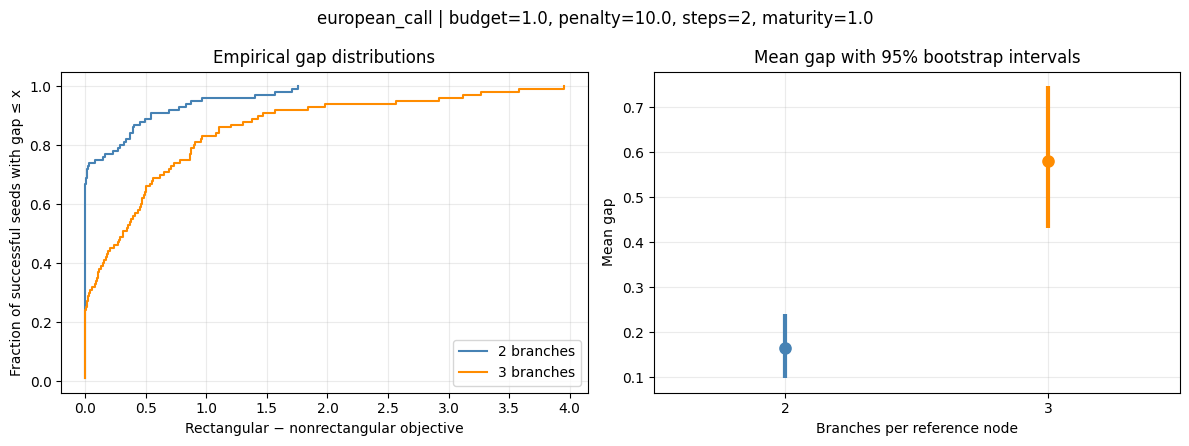

In [17]:
# Compare the full distributions and the estimated means.

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

colors = {2: "steelblue", 3: "darkorange"}

for branches in [2, 3]:
    group = combined_results.loc[
        (combined_results["branches"] == branches)
        & (combined_results["status"] == "ok")
    ]

    sorted_gaps = np.sort(group["gap"].to_numpy(dtype=float))
    cumulative_fraction = (
        np.arange(1, len(sorted_gaps) + 1) / len(sorted_gaps)
    )

    axes[0].step(
        sorted_gaps,
        cumulative_fraction,
        where="post",
        color=colors[branches],
        label=f"{branches} branches",
    )

    summary_row = branch_summary.loc[branches]

    axes[1].vlines(
        branches,
        summary_row["CI95_lower"],
        summary_row["CI95_upper"],
        color=colors[branches],
        linewidth=3,
    )

    axes[1].scatter(
        branches,
        summary_row["mean_gap"],
        color=colors[branches],
        s=65,
        zorder=3,
    )

axes[0].set_xlabel("Rectangular − nonrectangular objective")
axes[0].set_ylabel("Fraction of successful seeds with gap ≤ x")
axes[0].set_title("Empirical gap distributions")
axes[0].legend()

axes[1].set_xticks([2, 3])
axes[1].set_xlim(1.5, 3.5)
axes[1].set_xlabel("Branches per reference node")
axes[1].set_ylabel("Mean gap")
axes[1].set_title("Mean gap with 95% bootstrap intervals")

for ax in axes:
    ax.grid(alpha=0.25)

fig.suptitle(
    f"{PAYOFF} | budget={BUDGET}, penalty={PENALTY}, "
    f"steps={N_STEPS}, maturity={MATURITY}"
)

fig.tight_layout()
fig.savefig(
    comparison_dir / "branch_comparison.pdf",
    bbox_inches="tight",
)
plt.show()